In [1]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
from statsmodels.api import OLS
import sklearn.model_selection as skm
import sklearn.linear_model as skl
from sklearn.preprocessing import StandardScaler
from ISLP import load_data
from ISLP.models import ModelSpec as MS
from functools import partial

In [2]:
from sklearn.pipeline import Pipeline #step-by-step recipe
from sklearn.decomposition import PCA #It reduces the number of features by combining them into new ones (called principal components) that keep the most important information.
from sklearn.cross_decomposition import PLSRegression #Partial Least Squares Regression, selects variables explain variance
from ISLP.models import \
     (Stepwise,
      sklearn_selected,
      sklearn_selection_path)
from l0bnb import fit_path #does subset selection (finds the path)
import statsmodels.api as sm

In [13]:
df = pd.read_stata("bechtel_liesch_scheve_pnas.dta")

In [14]:
# Outcome and treatment
Y = "taken"
D = "advantagIneq"

# Baseline covariates
X = [
    "age", "male", "GE",
    "inc_low", "inc_middle",
    "edu_low", "edu_middle",
    "left_ideology", "right_ideology",
    "employed", "unemployed", "retired", "inEducation"
]

# Keep advantageous inequality and equality groups
df2 = df.loc[
    (df["advantagIneq"] == 1) | (df["equality"] == 1),
    [Y, D] + X
].dropna().copy()

In [16]:
model = MS(df2.columns.drop("taken"), intercept=True)
D = model.fit_transform(df2).drop(columns="intercept")

X = D.to_numpy(dtype=float)
Y = np.asarray(df2["taken"], dtype=float)

# Standardize for coefficient paths
Xs = StandardScaler().fit_transform(X)

K = 5
kfold = skm.KFold(K, shuffle=True, random_state=0)

In [17]:
lambdas = 10**np.linspace(8, -2, 100) / Y.std()
soln_array = skl.ElasticNet.path(Xs, Y, l1_ratio=0., alphas=lambdas)[1]
 
pipe = Pipeline([('scaler', StandardScaler()), ('ridge', skl.ElasticNet(l1_ratio=0))])
grid = skm.GridSearchCV(pipe, {'ridge__alpha': lambdas}, cv=kfold,
                         scoring='neg_mean_squared_error').fit(X, Y)
 
ridgeCV = skl.ElasticNetCV(alphas=lambdas, l1_ratio=0, cv=kfold)
pipeCV  = Pipeline([('scaler', StandardScaler()), ('ridge', ridgeCV)]).fit(X, Y)
tuned = pipeCV.named_steps['ridge']; tuned.alpha_, tuned.mse_path_.mean(1).min(), tuned.coef_

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:701: UserWarning: Coordinate descent without L1 regularization may lead to unexpected results and is discouraged. Set l1_ratio > 0 to add L1 regularization.
  model = cd_fast.enet_coordinate_descent_gram(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:701: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.628e+05, tolerance: 1.126e+02
  model = cd_fast.enet_coordinate_descent_gram(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:701: UserWarning: Coordinate descent without L1 regularization may lead to unexpected results and is discouraged. Set l1_ratio > 0 to add L1 regularizati

(np.float64(0.05812280203163658),
 np.float64(300.8276416588175),
 array([-4.76977791,  0.34102776,  0.39952595, -0.26207058, -0.13857657,
        -0.10226974,  0.37130149,  0.48640963,  0.07288276,  0.36027686,
         0.24096572,  0.13544274, -0.54746067,  0.05062494]))

In [19]:
soln_path = pd.DataFrame(soln_array.T,
                         columns=D.columns,
                         index=-np.log(lambdas))
soln_path.index.name = 'negative log(lambda)'
soln_path

,advantagIneq,age,male,GE,inc_low,inc_middle,edu_low,edu_middle,left_ideology,right_ideology,employed,unemployed,retired,inEducation
negative log(lambda),,,,,,,,,,,,,,
-15.528967,-9.054912e-07,-1.832546e-08,8.464329e-08,-4.281804e-08,-1.249721e-08,-3.294279e-08,2.938291e-08,-3.793512e-09,-3.569232e-09,6.991528e-08,7.775553e-08,8.468160e-09,-8.309852e-08,-1.002884e-08
-15.296382,-1.142600e-06,-2.312411e-08,1.068077e-07,-5.403024e-08,-1.576969e-08,-4.156908e-08,3.707703e-08,-4.786864e-09,-4.503858e-09,8.822308e-08,9.811635e-08,1.068561e-08,-1.048584e-07,-1.265496e-08
-15.063798,-1.441798e-06,-2.917931e-08,1.347760e-07,-6.817842e-08,-1.989909e-08,-5.245423e-08,4.678590e-08,-6.040330e-09,-5.683223e-09,1.113249e-07,1.238088e-07,1.348371e-08,-1.323163e-07,-1.596875e-08
-14.831214,-1.819343e-06,-3.682009e-08,1.700681e-07,-8.603140e-08,-2.510981e-08,-6.618972e-08,5.903710e-08,-7.622019e-09,-7.171411e-09,1.404761e-07,1.562289e-07,1.701451e-08,-1.669642e-07,-2.015027e-08
-14.598629,-2.295750e-06,-4.646167e-08,2.146015e-07,-1.085593e-07,-3.168498e-08,-8.352194e-08,7.449636e-08,-9.617877e-09,-9.049289e-09,1.772607e-07,1.971385e-07,2.146988e-08,-2.106849e-07,-2.542676e-08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6.566547,-5.042904e+00,4.211990e-01,4.237102e-01,-2.853825e-01,-1.722298e-01,-1.215296e-01,4.609432e-01,5.898613e-01,8.666880e-02,3.866741e-01,2.429239e-01,1.468868e-01,-6.281557e-01,6.938769e-02
6.799131,-5.044392e+00,4.216876e-01,4.238454e-01,-2.855137e-01,-1.724551e-01,-1.216660e-01,4.615091e-01,5.904989e-01,8.675120e-02,3.868238e-01,2.429196e-01,1.469452e-01,-6.286496e-01,6.950042e-02
7.031716,-5.045571e+00,4.220755e-01,4.239526e-01,-2.856176e-01,-1.726342e-01,-1.217744e-01,4.619584e-01,5.910051e-01,8.681659e-02,3.869425e-01,2.429160e-01,1.469915e-01,-6.290417e-01,6.958988e-02


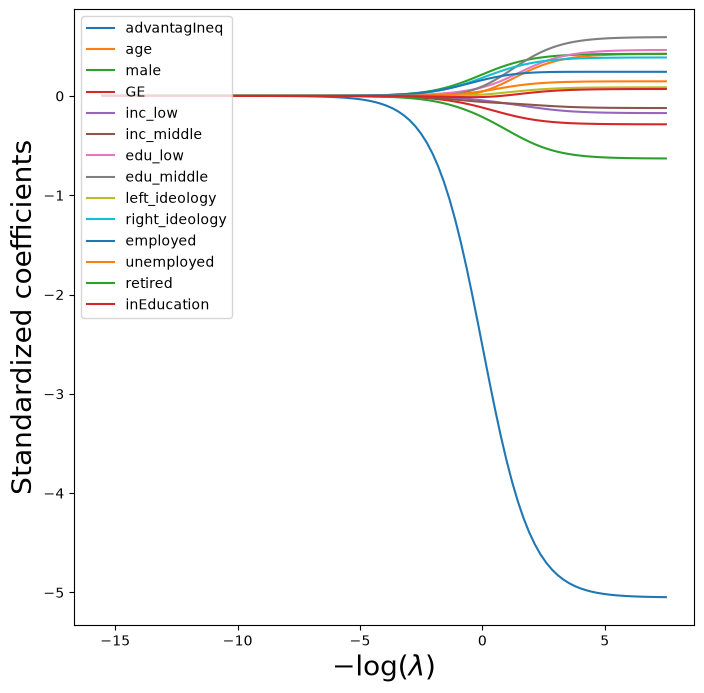

In [20]:
path_fig, ax = subplots(figsize=(8,8))
soln_path.plot(ax=ax, legend=False)
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Standardized coefficients', fontsize=20)
ax.legend(loc='upper left');

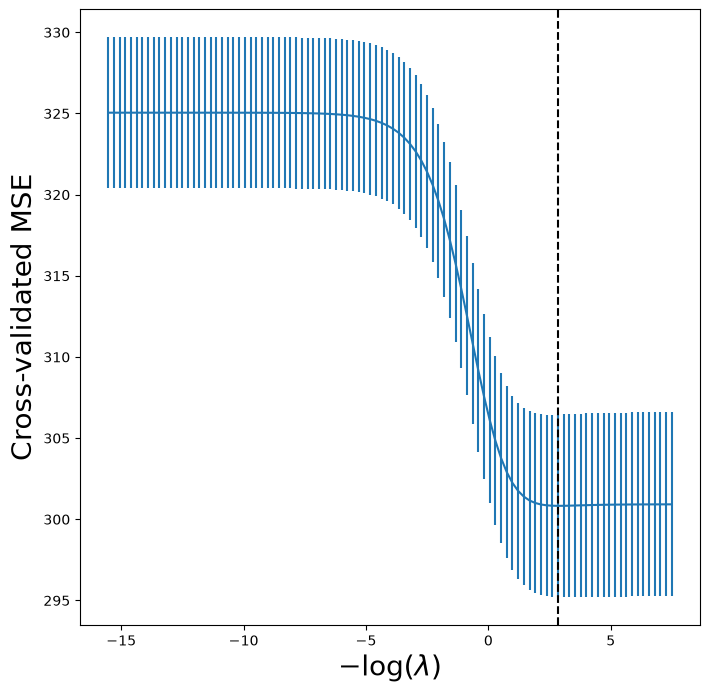

In [23]:
tuned_ridge = pipeCV.named_steps['ridge']
ridgeCV_fig, ax = subplots(figsize=(8,8))
ax.errorbar(-np.log(lambdas),
            -grid.cv_results_['mean_test_score'],
            yerr=grid.cv_results_['std_test_score'] / np.sqrt(K))
ax.axvline(-np.log(grid.best_params_['ridge__alpha']), c='k', ls='--')
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20);